# 32 A second Swift sample: Li & Mao's precursors

Li & Mao (2022, ApJ 928, 152) searched the 1006 bursts of the third Swift-BAT catalogue by eye, and kept the 52 long ones that have a
redshift and a precursor seen in every BAT channel (`shared/limao2022_precursors.csv`). They fitted each episode of the light curve with a
pulse shape and compared the timing of precursors and main bursts, but they measured no spectra. 14 of the 52 are Burlon et al.'s (notebook
30), so 38 haven't had their precursor's spectrum looked at like this before.

Here the BAT pipeline of notebook 30 runs on all 52, with nothing taken from their paper but the list. Our rule (zhu2026) finds the
precursor and main emission in BAT's mask-weighted light curve (256 ms bins), both are fitted with a power law in 15-150 keV, and the
precursor's luminosity in the rest-frame 15-150 keV band, from our own fit, is set against the shattering-flare budget and the two merger
precursors. Their pulse fits are only used to check that we find the same precursors.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import quad
from astropy import units as u
from astropy.cosmology import Planck18
from instruments import bat_sample as S

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
FIGURES = Path("figures")
spans, info = S.limao_spans()
burlon = set(S.read_sample().grb)
path = S.OUT / "limao2022.csv"
table = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=["grb"])
missing = sorted(set(info.index) - set(table.grb))
if missing:                                     # bursts bat_sample.limao hasn't been run on yet are measured here
    table = S.limao(missing)
ours = table.set_index("grb")
ours["in_burlon"] = ours.index.isin(burlon)
print(len(ours), "bursts,", int(ours.in_burlon.sum()), "of them Burlon et al.'s; not measured:",
      ours.note.dropna().to_dict() if "note" in ours else "none")

52 bursts, 14 of them Burlon et al.'s; not measured: none


## 1. Their precursors found from BAT's light curve

Their precursor counts as found when ours overlaps the span of their precursor pulses (from the first pulse's start to about 5% of the last
one's peak, `t_s + tau_p + 3 tau_d`).

In [2]:
ours["d_start"] = np.where(ours.found.eq(True), ours.pe_start - ours.their_pre_start, np.nan)
cols = ["z_printed", "type", "their_pre_start", "their_pre_stop", "pe_start", "pe_stop", "their_main_start", "me_start", "me_stop", "found", "d_start"]
print(ours[cols].round(2).to_string())
f = ours.found.eq(True)
print(f"their precursor found in {int(f.sum())} of {int(ours.found.notna().sum())} bursts "
      f"({int(f[ours.in_burlon].sum())} of {int(ours.in_burlon.sum())} of Burlon et al.'s); median |start difference| {ours.d_start.abs().median():.1f} s")

           z_printed   type  their_pre_start  their_pre_stop  pe_start  pe_stop  their_main_start  me_start  me_stop  found  d_start
grb                                                                                                                                 
GRB050315      1.949    XRR           -60.43          -15.12    -55.98   -47.28            -10.16     -6.32    73.55   True     4.45
GRB050318       1.44    XRR            -1.80            4.61     -0.60     7.34             19.52     23.46    31.91   True     1.20
GRB050319       3.24    XRR          -135.52          -81.80   -134.00   -97.65              0.10      0.14    52.62   True     1.52
GRB050401       2.90  C-GRB            -9.99           11.64     -7.69    -4.10             23.41     -2.06    32.76   True     2.30
GRB050502B       5.2    XRR           -18.84           -1.59    -17.34    -8.38             -7.61     -3.52     2.62   True     1.50
GRB050726       <3.5  C-GRB          -178.56         -165.60   -179.6

From BAT's light curve alone our rule finds their precursor in 46 of the 52 bursts, all 14 of Burlon et al.'s among them, with starts a
median 2.9 s from theirs (their pulse starts are fitted onsets, which come before a precursor rises above the background). In all six it
misses (GRB 080928, 120211A, 120224A, 130907A, 150120B and 150413A), the rule finds no quiet gap before the main emission at 256 ms, so it
takes the precursor as part of the main emission. In two of them (GRB 080928 and 130907A) BAT's event data also have a break, and the stretch
the rule reads starts after their precursor.

GRB 111228A, which my GBM run couldn't measure, comes out with a precursor of 25.6 s, a gap of 20.2 s and a main emission of 28.2 s in BAT,
against Zhu et al.'s 8.6, 5.4 and 20.1 s from GBM. BAT sees the precursor, but with its softer band and coarser bins the durations only
agree roughly.

GRB 111228A is the one burst of Zhu et al.'s sample that GBM couldn't measure here, because its TTE data start at -33.7 s, after the burst
has begun (notebook 23). BAT's event data start at -239 s, so its episodes under the same rule can be set next to Zhu et al.'s Table 1. BAT
sees 15-150 keV rather than GBM's 8-1000 keV, and the bins are 256 ms rather than their 8 ms, so only rough agreement is expected.

In [3]:
if "GRB111228A" in ours.index and np.isfinite(ours.loc["GRB111228A", "pe_start"]):
    r = ours.loc["GRB111228A"]
    z1 = pd.read_csv("shared/zhu2026_table1.csv", comment="#", dtype={"GRB": str}).set_index("GRB").loc["111228A"]
    print(f"BAT, our rule: precursor {r.pe_start:.2f} to {r.pe_stop:.2f} s ({r.pe_stop - r.pe_start:.2f} s), gap {r.me_start - r.pe_stop:.2f} s, "
          f"main emission {r.me_start:.2f} to {r.me_stop:.2f} s ({r.me_stop - r.me_start:.2f} s)")
    print(f"Zhu et al., GBM: T100 of the precursor {z1.T100_PE} s, gap {z1.T100_QE1} s, main emission {z1.T100_ME} s; their type {z1.Type}")
else:
    print("GRB 111228A has no precursor under our rule in BAT's light curve" if "GRB111228A" in ours.index else "no BAT data for GRB 111228A here")

BAT, our rule: precursor -13.28 to 12.32 s (25.60 s), gap 20.22 s, main emission 32.54 to 60.70 s (28.16 s)
Zhu et al., GBM: T100 of the precursor 8.56 s, gap 5.392 s, main emission 20.136 s; their type II


## 2. Spectra of our windows

Each precursor and main emission our rule finds is fitted with a power law in 15-150 keV, with the response averaged over the window as in
notebook 27. The energy flux in the observed band that is 15-150 keV in the rest frame comes from the same fit, extrapolated below 15 keV
for the more distant bursts as Burlon et al. did, and it gives the luminosity L = 4 pi d_L^2 F.

In [4]:
spec = ours[ours.found.eq(True)].copy()
spec["softer_by"] = spec.me_index - spec.pe_index                  # positive: the precursor is softer
spec["softer_sigma"] = spec.softer_by / np.hypot(spec.pe_err, spec.me_err)
print(spec[["z_printed", "pe_index", "pe_err", "me_index", "me_err", "softer_by", "softer_sigma", "pe_L_rest_15_150", "pe_duration_rest_s"]].round(3).to_string())
ok = spec.dropna(subset=["softer_sigma"])
print(f"precursor softer than its main emission by more than 2 sigma in {int((ok.softer_sigma > 2).sum())} of {len(ok)}, harder in "
      f"{int((ok.softer_sigma < -2).sum())}; softer by {ok.softer_by.median():.2f} at the median (range {ok.softer_by.min():.2f} to {ok.softer_by.max():.2f})")

           z_printed  pe_index  pe_err  me_index  me_err  softer_by  softer_sigma  pe_L_rest_15_150  pe_duration_rest_s
grb                                                                                                                    
GRB050315      1.949    -1.748   0.201    -2.145   0.049     -0.397        -1.920      4.833992e+50               2.952
GRB050318       1.44    -2.113   0.120    -1.896   0.042      0.217         1.701      5.058550e+50               3.252
GRB050319       3.24    -1.954   0.096    -2.203   0.135     -0.248        -1.499      1.347966e+51               8.574
GRB050401       2.90    -1.353   0.102    -1.441   0.051     -0.088        -0.771      1.056610e+52               0.919
GRB050502B       5.2    -1.750   0.185    -1.552   0.073      0.199         0.997      2.555379e+51               1.445
GRB050726       <3.5    -1.901   0.363    -0.990   0.117      0.910         2.384               NaN                 NaN
GRB050820A     2.612    -1.748   0.075  

GRB 211211A's precursor, measured the same way with BAT (notebook 30), is softer than its main emission by 0.78 +- 0.10. GRB 230307A's,
folded into BAT's band from GBM's fits, would be softer by 0.0 than its main emission as a whole, and by 0.54 than its first bright window,
0.32-3 s (notebook 30).

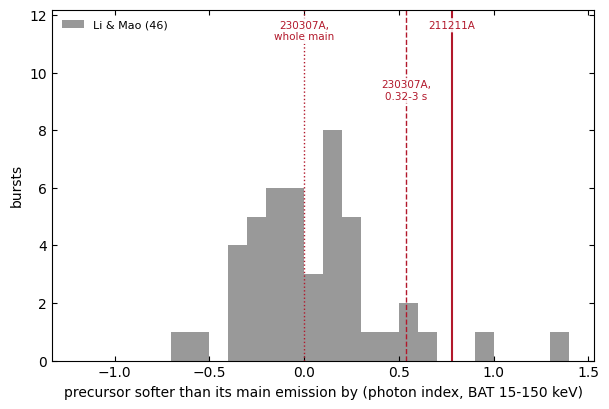

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 4.2))
bins = np.arange(-1.2, 1.41, 0.1)
ax.hist(ok.softer_by, bins=bins, color="0.6", label=f"Li & Mao ({len(ok)})")
ax.set_ylim(0, 1.45 * ax.get_ylim()[1])
top = ax.get_ylim()[1]
box = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9)
for x, ls, lw, text, y in ((0.78, "-", 1.5, "211211A", 0.97), (0.0, ":", 1.0, "230307A,\nwhole main", 0.97), (0.54, "--", 1.0, "230307A,\n0.32-3 s", 0.80)):
    ax.axvline(x, color="#b2182b", lw=lw, ls=ls)
    ax.text(x, y * top, text, ha="center", va="top", fontsize=7.5, color="#b2182b", bbox=box)
ax.set(xlabel="precursor softer than its main emission by (photon index, BAT 15-150 keV)", ylabel="bursts")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "32_softness.png", dpi=150); plt.show()

In BAT's band Li & Mao's precursors look like their main emissions, as Burlon et al.'s do. The median difference in photon index is 0.01,
and 7 of 46 are softer by more than 2 sigma and 7 harder. Two are softer than GRB 211211A's 0.78. GRB 061202's precursor is softer than its
main emission by 1.35 +- 0.30 (4.5 sigma), but it lasts 6 s in its rest frame (z = 2.25) at about 8.5e50 erg/s, 43 times what a
shattering flare can supply, so it's soft like 211211A's precursor and long and bright like the other Swift ones. GRB 050726's is softer by
0.91 +- 0.38 (2.4 sigma), but it comes 170 s before the main emission and the redshift is only a limit. (GRB 050820A's 0.58 at 6.7 sigma is
against only the first 17 s of a main emission that BAT's event data cut off, as in notebook 30.) The most significant harder one, GRB
080411 (-0.55, 23 sigma), is a bright first episode that Li & Mao count as a precursor, followed by a long main emission that softens as it
goes: the usual hard-to-soft evolution. As in notebook 30, BAT's band would show a precursor as soft as GRB 211211A's, but not one like GRB
230307A's.

## 3. Energy and timescale

As in notebook 30, the tidal energy rate a shattering flare would need is L/0.2, against about 1e50 erg/s at the fiducial values, so the line
is the luminosity such a flare could give. The merger precursors are in the same band, from GBM's fits (notebooks 12 and 14). Burlon et
al.'s precursors are shown on their windows with our fits (notebook 30), and their own printed energies come out lower.

In [6]:
def band(e, a, b, ep):
    e0 = ep / (2 + a); ec = (a - b) * e0
    return np.where(e < ec, (e / 100) ** a * np.exp(-e / e0), ((a - b) * e0 / 100) ** (a - b) * np.exp(b - a) * (e / 100) ** b)


def cpl(e, a, ep):
    return (e / 100) ** a * np.exp(-e * (2 + a) / ep)


mergers = []
for burst, z, f in (("GRB 230307A", 0.065, "shared/epeak_230307A.csv"), ("GRB 211211A", 0.0762, "shared/epeak_211211A.csv")):
    r = pd.read_csv(f, comment="#").set_index("label").loc["pre"]
    shape = (lambda e, r=r: band(e, r.alpha, r.beta, r.Epeak_keV)) if r.model == "Band" else (lambda e, r=r: cpl(e, r.alpha, r.Epeak_keV))
    energy = lambda lo, hi: quad(lambda x: np.exp(2 * x) * shape(np.exp(x)), np.log(lo), np.log(hi), limit=300)[0]
    k = energy(15 / (1 + z), 150 / (1 + z)) / energy(10, 1000)
    mergers.append(dict(burst=burst, duration_rest_s=(r.t_stop - r.t_start) / (1 + z),
                        L=4 * np.pi * Planck18.luminosity_distance(z).to(u.cm).value ** 2 * r.flux_10_1000keV_erg_cm2_s * k))
mergers = pd.DataFrame(mergers)
b08 = pd.read_csv("results/bat_sample/burlon2008.csv")            # notebook 30: their windows, our fits
b08 = b08[b08.episode.str.startswith("pre") & b08.eiso_15_150_rest.notna()].assign(duration_rest_s=lambda t: (t.t2_s - t.t1_s) / (1 + t.z))
b08["L"] = b08.eiso_15_150_rest / b08.duration_rest_s
lm = spec.dropna(subset=["pe_L_rest_15_150"])
need = lm.pe_L_rest_15_150 / 0.2 / 1e50
print(f"Li & Mao's precursors (our windows and fits): rest-frame duration median {lm.pe_duration_rest_s.median():.1f} s "
      f"({lm.pe_duration_rest_s.min():.2f}-{lm.pe_duration_rest_s.max():.1f}); L(15-150 keV) median {lm.pe_L_rest_15_150.median():.1e} erg/s; "
      f"{need.min():.2f}-{need.max():.0f} times the fiducial rate; below it: {list(lm.index[need < 1])}")
both = lm.join(b08.drop_duplicates("grb").set_index("grb")[["L"]].rename(columns={"L": "L_their_window"}), how="inner")
if len(both):
    print(f"on Burlon et al.'s bursts, L on our windows over L on theirs (both our fits): median {both.eval('pe_L_rest_15_150 / L_their_window').median():.2f} "
          f"over {len(both)}")

Li & Mao's precursors (our windows and fits): rest-frame duration median 3.6 s (0.54-46.3); L(15-150 keV) median 1.1e+51 erg/s; 2.36-528 times the fiducial rate; below it: []
on Burlon et al.'s bursts, L on our windows over L on theirs (both our fits): median 1.01 over 14


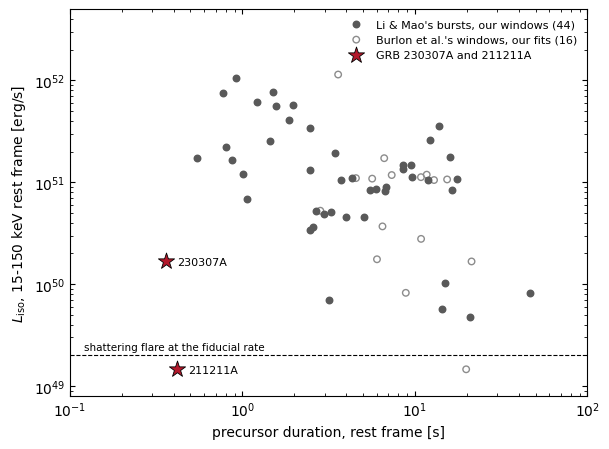

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.scatter(lm.pe_duration_rest_s, lm.pe_L_rest_15_150, s=22, color="0.35", label=f"Li & Mao's bursts, our windows ({len(lm)})", zorder=2)
ax.scatter(b08.duration_rest_s, b08.L, s=22, facecolor="none", edgecolor="0.55", label=f"Burlon et al.'s windows, our fits ({len(b08)})")
ax.scatter(mergers.duration_rest_s, mergers.L, s=150, marker="*", color="#b2182b", edgecolor="k", lw=0.6, zorder=3, label="GRB 230307A and 211211A")
for _, r in mergers.iterrows():
    ax.annotate(r.burst.replace("GRB ", ""), (r.duration_rest_s, r.L), textcoords="offset points", xytext=(8, -3), fontsize=8)
ax.axhline(0.2e50, color="k", ls="--", lw=0.8)
ax.annotate("shattering flare at the fiducial rate", (0.12, 0.2e50), textcoords="offset points", xytext=(0, 4), fontsize=7.5)
ax.set(xscale="log", yscale="log", xlabel="precursor duration, rest frame [s]", ylabel=r"$L_{\rm iso}$, 15-150 keV rest frame [erg/s]", xlim=(0.1, 100), ylim=(8e48, 5e52))
ax.legend(fontsize=8, frameon=False, loc="upper right")
ax.tick_params(which="both", direction="in", top=True, right=True)
fig.tight_layout(); fig.savefig(FIGURES / "32_precursor_power.png", dpi=150); plt.show()

The larger sample tells the same story as notebook 30. Li & Mao's precursors, on our windows and fits, last 0.5-46 s in their rest frames
(a median of 3.6 s) at a median 1.1e51 erg/s in 15-150 keV: 2.4 to 530 times what a shattering flare can supply at the fiducial values.
None is below it, unlike GRB 211211A's precursor (0.73 times), and the five that need less than GRB 230307A's 8.4 times (GRB 060729,
071010B, 111228A, 140512A and 150323A) last 3-46 s, not 0.4 s. On Burlon et al.'s bursts our windows and theirs give the same luminosities
(a median ratio of 1.01).

The selection is as strong as for Burlon et al.'s sample. By the reach estimated in notebook 30, a precursor as faint and short as GRB
230307A's would only be seen out to z of about 0.8, and one like GRB 211211A's to about 0.3, and only 4 of the 52 bursts are nearer than 0.8
(none nearer than 0.3). So BAT's precursors of distant long bursts are long and luminous, and whether short, faint ones like the mergers'
are rare among long bursts can't be told from them.